# CoSTA on the canonical heat rod of Modules 22 and 25

The other hybrid-modelling modules of Part V solve one and the same problem, defined once in
`pyutils/benchmarks/heat1d.py`:

$$\frac{\partial T}{\partial t}=\alpha\,\frac{\partial^2 T}{\partial x^2},\qquad x\in[0,1],\qquad
T(0,t)=T(1,t)=0,\qquad \alpha=0.1,$$

with initial profiles from the eight-mode sine family

$$a(x)=\sum_{k=1}^{8}c_k\sin(k\pi x),\qquad c_k\sim\mathcal N\!\left(0,\tfrac{1}{k^2}\right),$$

the FTCS march of Module 01 on $128$ points as the reference solver, and the horizon $t_{\mathrm f}=0.05$ of the
DeepONet module. Module 22 fits a PINN to the first member of the family; Module 25 learns the solution operator
$a\mapsto T(\cdot,t_{\mathrm f})$ from sensor readings. This notebook puts CoSTA on the same rod, so the three
methods can be compared on identical data.

The **physics-based model (PBM)** here is the right equation with the wrong parameter: the same FTCS march, same
grid, same time step, but a diffusivity $\alpha_{\text{PBM}}=0.07$, thirty percent too low. In the taxonomy of this
module that is **Case 2, an inaccurate parameter**. CoSTA keeps the solver and learns the corrective source
$\sigma_{\boldsymbol{\theta}}$ that the wrong-parameter step is missing, from the local stencil of the current state.
The protocol is the one of `costa_heat_pde.ipynb`: split by trajectory, fit on training rows, select on validation
rollouts, test once.

The prose narrates the **default** run. Change the values below and *Run All*; every figure, table and saved
result follows. Checks that quote the default numbers are skipped when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0                        # network initialization seed
ALPHA_PBM = 0.07                # diffusivity of the PBM (the reference uses heat1d.ALPHA = 0.1)
T_F = 0.05                      # horizon; must equal heat1d.T_F so that the rod is the one of Module 25
N_TRAIN, N_VAL, N_TEST = 60, 20, 20          # profiles per role
SEED_TRAIN, SEED_VAL, SEED_TEST = 1, 2, 3    # family seeds per role (disjoint draws)
BUMP_X0, BUMP_W = 0.35, 0.04    # out-of-family test profile exp(-(x-x0)^2/(2 w^2)), as in Module 25
FEATURES = 'stencil'            # 'stencil' = [T_{i-1}, T_i, T_{i+1}];  'stencil+x' adds x_i
BASIS = 'difference'            # how the stencil is presented: 'difference' = (value, slope, curvature); 'raw'
HIDDEN = [40, 40]
LR, MAX_STEPS, BATCH = 2e-3, 6000, 8192      # Adam on mini-batches; learning rate halves every 2000 steps
VAL_EVERY = 200                 # validation interval [steps]
PATIENCE = 8                    # stop after this many validations without improvement
MIN_REL_IMPROVEMENT = 0.01      # an improvement must beat the best by 1 %
SHOW = [0, 7, 14]               # test profiles drawn in the result figure
RUN_RAW_ABLATION = True         # also train on the raw stencil (same information, worse conditioning)
RUN_SOURCE_CASE = True          # second case: the reference also has a source q(x) the PBM omits
Q_AMP = 20.0                    # q(x) = Q_AMP sin(2 pi x)
RUN_DATA_BASELINE = True        # data-only map from M_SENSORS readings of a(x) to T(x, t_f)
M_SENSORS = 40                  # sensors of the data-only map (Module 25 uses 40)
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, ALPHA_PBM=0.07, T_F=0.05, N_TRAIN=60, N_VAL=20, N_TEST=20, SEED_TRAIN=1, SEED_VAL=2,
                SEED_TEST=3, BUMP_X0=0.35, BUMP_W=0.04, FEATURES='stencil', BASIS='difference', HIDDEN=[40, 40],
                LR=2e-3, MAX_STEPS=6000, BATCH=8192, VAL_EVERY=200, PATIENCE=8, MIN_REL_IMPROVEMENT=0.01)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

### Setup: the rod, the reference and the PBM step

Everything about the rod is imported, not redefined. `heat1d.steps` gives the step count of the reference march
($202$ steps to $t_{\mathrm f}=0.05$ at CFL number $0.4$); the PBM uses the **same** $\Delta t$ and grid, so the two
marches differ in $\alpha$ only. The PBM interior update with an added source $\boldsymbol{\sigma}^n$ is

$$T^{n+1}_i=T^n_i+\Delta t\left(\alpha_{\text{PBM}}\,\frac{T^n_{i+1}-2T^n_i+T^n_{i-1}}{\Delta x^2}+\sigma^n_i\right),$$

with $T^{n+1}_0=T^{n+1}_{N-1}=0$. With $\boldsymbol{\sigma}^n=\mathbf 0$ it is exactly the PBM.

In [2]:
import sys, os, copy, json, time
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils.pinn_core import MLP
from pyutils import save_dual, fg, muted
from pyutils.benchmarks import heat1d
torch.set_default_dtype(torch.float64)
pc.set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
DATA = os.path.abspath(os.path.join('..', 'data')); os.makedirs(DATA, exist_ok=True)
RESULTS_FILE = os.path.join(DATA, 'costa_heat_rod_results.json')

assert T_F == heat1d.T_F, 'the horizon must be the one of the canonical rod'
ALPHA = heat1d.ALPHA
x = heat1d.X; N_X = len(x); dx = x[1] - x[0]; n_int = N_X - 2
N_STEPS, dt = heat1d.steps(T_F)
print(f'rod: alpha = {ALPHA}, {N_X} points, dx = {dx:.4e}; {N_STEPS} FTCS steps of dt = {dt:.4e} to t_f = {T_F}')
print(f'PBM: alpha_pbm = {ALPHA_PBM} ({100*(ALPHA_PBM/ALPHA - 1):+.0f} %), same grid and time step')
print(f'reference check: max relative L2 error of FTCS vs the analytic series {heat1d.check_reference():.1e}')

def lap(T):
    """Discrete Laplacian at the interior nodes."""
    return (T[:-2] - 2*T[1:-1] + T[2:]) / dx**2

def step(Tn, src_int):
    """One explicit FTCS step of the PBM with an interior source added."""
    Tnew = Tn.copy()
    Tnew[1:-1] = Tn[1:-1] + dt*(ALPHA_PBM*lap(Tn) + np.asarray(src_int, float))
    Tnew[0] = Tnew[-1] = 0.0
    return Tnew

def reference(u0, q=None):
    """Reference trajectory from heat1d.ftcs, all time levels; shape (N_STEPS+1, N_X)."""
    T_end, traj = heat1d.ftcs(u0, T_F, ALPHA, q=q, snapshots=[k*dt for k in range(N_STEPS + 1)])
    traj = np.array(traj); assert np.array_equal(traj[-1], T_end)
    return traj

def rollout(u0, correction=None):
    """Recursive simulation of the PBM from an initial profile, returning the final state.

    The model's own previous state is the only input to the correction: the reference is never consulted here.
    """
    T = np.asarray(u0, float).copy(); T[0] = T[-1] = 0.0
    for n in range(N_STEPS):
        src = np.zeros(n_int) if correction is None else correction(T)
        T = step(T, src)
    return T

rod: alpha = 0.1, 128 points, dx = 7.8740e-03; 202 FTCS steps of dt = 2.4752e-04 to t_f = 0.05
PBM: alpha_pbm = 0.07 (-30 %), same grid and time step
reference check: max relative L2 error of FTCS vs the analytic series 9.6e-04


## 1. Partition whole trajectories first

A **case** is one initial profile, i.e.\ one coefficient vector $\boldsymbol{c}\in\mathbb R^8$, and the trajectory
it generates. Cases are drawn from the family with three different seeds and assigned to roles before any sample
is built, so that every stencil at every time level of a trajectory stays in that trajectory's role. One profile
from outside the family, the Gaussian bump $\exp(-(x-0.35)^2/(2\cdot0.04^2))$ that Module 25 uses as its
out-of-distribution input, is kept as an extra test.

In [3]:
C_TRAIN = heat1d.sample_family(N_TRAIN, SEED_TRAIN)
C_VAL = heat1d.sample_family(N_VAL, SEED_VAL)
C_TEST = heat1d.sample_family(N_TEST, SEED_TEST)
assert len({SEED_TRAIN, SEED_VAL, SEED_TEST}) == 3
U0 = {role: np.array([heat1d.profile(c, x) for c in C]) for role, C in
      [('train', C_TRAIN), ('val', C_VAL), ('test', C_TEST)]}
U0['bump'] = np.exp(-(x - BUMP_X0)**2 / (2*BUMP_W**2))[None, :]
for role, U in U0.items():
    print(f'{role:6s} {len(U):3d} profiles')

train   60 profiles
val     20 profiles
test    20 profiles
bump     1 profiles


## 2. Labels: the exact discrete corrective source

For a reference step $\mathbf T^{*,n}\to\mathbf T^{*,n+1}$ the correction that makes the PBM step land exactly on
the reference is the residual of the PBM's explicit update evaluated on the reference,

$$\sigma^{*,n}_i=\frac{T^{*,n+1}_i-T^{*,n}_i}{\Delta t}-\alpha_{\text{PBM}}\,\frac{T^{*,n}_{i+1}-2T^{*,n}_i+T^{*,n}_{i-1}}{\Delta x^2}.$$

Because the reference is the same explicit march with $\alpha$ instead of $\alpha_{\text{PBM}}$, this label is,
to round-off, $(\alpha-\alpha_{\text{PBM}})$ times the discrete Laplacian of the current state: the missing physics
is **thirty percent of the diffusion term**, a linear function of the stencil. The input of the network is the
stencil at level $n$; the label needs level $n+1$, which exists when building the training set but not when
predicting.

**How the stencil is presented matters.** The three temperatures of a stencil are nearly equal, and the label is a
tiny combination of them (the second difference is of order $\Delta x^2\,\partial_{xx}T\approx10^{-3}$ while the
temperatures are of order one). We therefore hand the network the same three numbers in the *difference basis*
$[T_i,\;(T_{i+1}-T_{i-1})/(2\Delta x),\;(T_{i+1}-2T_i+T_{i-1})/\Delta x^2]$: value, slope and curvature. This is an
invertible linear change of coordinates of the stencil, so no information is added or removed, but the
standardized columns are now well conditioned. The ablation in Section 6 trains on the raw stencil for comparison.

In [4]:
def label(Tn, Tn1):
    """Exact discrete corrective source for the PBM step Tn -> Tn1 (interior nodes)."""
    return (Tn1[1:-1] - Tn[1:-1])/dt - ALPHA_PBM*lap(Tn)

def features(T, kind=FEATURES, basis=BASIS):
    Tm, Tc, Tp = T[:-2], T[1:-1], T[2:]
    cols = [Tm, Tc, Tp] if basis == 'raw' else [Tc, (Tp - Tm)/(2*dx), (Tm - 2*Tc + Tp)/dx**2]
    if kind == 'stencil+x':
        cols.append(x[1:-1])
    return np.stack(cols, 1)

def dataset(trajs, kind=FEATURES, basis=BASIS):
    """Feature rows at level n and labels from levels n, n+1, for whole trajectories."""
    F, Y = [], []
    for R in trajs:
        for n in range(N_STEPS):
            F.append(features(R[n], kind, basis)); Y.append(label(R[n], R[n+1]))
    return np.vstack(F), np.concatenate(Y)[:, None]

t0 = time.time()
REF = {role: np.array([reference(u) for u in U]) for role, U in U0.items()}
print(f'reference trajectories built in {time.time()-t0:.1f} s')
for role in ['train', 'val', 'test']:
    err = heat1d.relative_l2(REF[role][:, -1], [heat1d.exact(c, x, T_F) for c in
                                                 {'train': C_TRAIN, 'val': C_VAL, 'test': C_TEST}[role]])
    print(f'  {role:6s} FTCS vs analytic series at t_f: max relative L2 {err.max():.1e}')

# one worked sample: training profile 0, time level n = 50, node i = 40
R0, n0, i0 = REF['train'][0], 50, 40
print(f'\nsample (profile 0, n={n0}, i={i0}, x={x[i0]:.3f})')
print('  stencil      =', np.round(features(R0[n0], basis='raw')[i0-1], 5))
print('  difference basis (value, slope, curvature) =', np.round(features(R0[n0])[i0-1], 3))
print(f'  label sigma* = {label(R0[n0], R0[n0+1])[i0-1]:.4f}   '
      f'(alpha - alpha_pbm) * curvature = {(ALPHA-ALPHA_PBM)*lap(R0[n0])[i0-1]:.4f}')

# sanity check 1: the exact correction reproduces the reference step
worst = max(np.abs(step(R[n], label(R[n], R[n+1])) - R[n+1]).max()
            for R in list(REF['train'][:5]) + list(REF['bump']) for n in range(N_STEPS))
print(f'exact correction, one step from the reference: max error {worst:.1e}')
assert worst < 1e-12
# sanity check 2: a zero correction is exactly the PBM (the switch-off identity)
zero = lambda T: np.zeros(n_int)
assert all(np.array_equal(rollout(u, zero), rollout(u)) for u in U0['test'])
print('zero correction reproduces the PBM bit for bit on all test profiles')

reference trajectories built in 0.1 s
  train  FTCS vs analytic series at t_f: max relative L2 1.4e-03
  val    FTCS vs analytic series at t_f: max relative L2 9.0e-04
  test   FTCS vs analytic series at t_f: max relative L2 8.2e-04

sample (profile 0, n=50, i=40, x=0.315)
  stencil      = [0.70569 0.71848 0.73001]
  difference basis (value, slope, curvature) = [  0.718   1.545 -20.218]
  label sigma* = -0.6065   (alpha - alpha_pbm) * curvature = -0.6065
exact correction, one step from the reference: max error 0.0e+00
zero correction reproduces the PBM bit for bit on all test profiles


Both checks pass: the exact label lands on the next reference state to round-off, and a zero correction is the PBM
rollout bit for bit. The worked sample shows why the basis matters: the three stencil temperatures agree to three
digits, while the label is proportional to their second difference.

## 3. Training with validation-based checkpoint selection

The standardization statistics are fitted on **training rows only**. The network
$\sigma_{\boldsymbol{\theta}}(\boldsymbol{q})$ is a tanh MLP trained by mini-batch Adam on the standardized correction
MSE; the training set has $60\times202\times126\approx1.5\times10^6$ rows, which is why full-batch steps are not
used here. Every `VAL_EVERY` steps we run the $20$ validation profiles recursively with the current network and
record the mean relative $L^2$ error at $t_{\mathrm f}$ (`heat1d.relative_l2`), the metric Modules 22 and 25
report. The checkpoint with the lowest validation rollout error is kept; training stops after `PATIENCE`
validations without a 1 % improvement.

In [5]:
def rel_l2_final(U, corr, R):
    """Mean relative L2 error at t_f of recursive rollouts from the profiles U against the reference finals R."""
    P = np.array([rollout(u, corr) for u in U])
    return float(np.mean(heat1d.relative_l2(P, R))) if np.all(np.isfinite(P)) else float('inf')

class Correction:
    """A trained correction: network plus the training-set standardization."""
    def __init__(self, net, stats, kind, basis):
        self.net, self.stats, self.kind, self.basis = net, stats, kind, basis
    def __call__(self, T):
        Fm, Fs, Ym, Ys = self.stats
        with torch.no_grad():
            z = torch.tensor((features(T, self.kind, self.basis) - Fm) / Fs)
            return self.net(z).numpy().ravel()*Ys + Ym

def fit_costa(ref, u0, seed=SEED, kind=FEATURES, basis=BASIS, verbose=False):
    """Train on ref['train'], select on rollouts from u0['val'] scored against ref['val'][:, -1]."""
    F, Y = dataset(ref['train'], kind, basis); Fv, Yv = dataset(ref['val'], kind, basis)
    Fm, Fs = F.mean(0), F.std(0); Ym, Ys = Y.mean(), Y.std()      # training rows only
    Ft, Yt = torch.tensor((F-Fm)/Fs), torch.tensor((Y-Ym)/Ys)
    Fvt, Yvt = torch.tensor((Fv-Fm)/Fs), torch.tensor((Yv-Ym)/Ys)
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    net = MLP([F.shape[1], *HIDDEN, 1]); corr = Correction(net, (Fm, Fs, Ym, Ys), kind, basis)
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=2000, gamma=0.5)
    hist = dict(step=[], train_mse=[], val_mse=[], val_rollout=[])
    best, best_step, best_state, waited = np.inf, 0, None, 0
    for k in range(MAX_STEPS + 1):
        if k % VAL_EVERY == 0 or k == MAX_STEPS:
            with torch.no_grad():
                tr = ((net(Ft) - Yt)**2).mean().item(); va = ((net(Fvt) - Yvt)**2).mean().item()
            vr = rel_l2_final(u0['val'], corr, ref['val'][:, -1])
            for key, val in zip(hist, (k, tr, va, vr)):
                hist[key].append(val)
            if vr < best*(1 - MIN_REL_IMPROVEMENT):
                best, best_step, best_state, waited = vr, k, copy.deepcopy(net.state_dict()), 0
            else:
                waited += 1
            if verbose:
                print(f'step {k:5d}  train mse {tr:.2e}  val mse {va:.2e}  val rollout rel. L2 {vr:.2e}')
            if waited >= PATIENCE or k == MAX_STEPS:
                break
        idx = torch.tensor(rng.integers(0, len(Ft), BATCH))
        opt.zero_grad(); loss = ((net(Ft[idx]) - Yt[idx])**2).mean(); loss.backward(); opt.step(); sched.step()
    net.load_state_dict(best_state)                       # restore the selected checkpoint
    net.eval()
    return corr, dict(hist=hist, best_step=best_step, best_val_rollout=best, stopped_at=k)

t0 = time.time()
costa, info = fit_costa(REF, U0, verbose=True)
T_TRAIN = time.time() - t0
print(f"selected checkpoint: step {info['best_step']} (validation rollout rel. L2 {info['best_val_rollout']:.2e}); "
      f"training stopped at step {info['stopped_at']}; {T_TRAIN:.0f} s")

# evaluating the model must not change it
w_before = [p.detach().clone() for p in costa.net.parameters()]
_ = rel_l2_final(U0['val'], costa, REF['val'][:, -1])
assert all(torch.equal(p, q) for p, q in zip(w_before, costa.net.parameters()))

step     0  train mse 2.08e+00  val mse 2.16e+00  val rollout rel. L2 1.17e-01


step   200  train mse 1.66e-02  val mse 1.13e-02  val rollout rel. L2 4.77e-03


step   400  train mse 3.41e-03  val mse 1.97e-03  val rollout rel. L2 1.74e-03


step   600  train mse 9.70e-04  val mse 6.37e-04  val rollout rel. L2 8.22e-04


step   800  train mse 5.45e-04  val mse 4.01e-04  val rollout rel. L2 6.59e-04


...

step  5200  train mse 1.51e-05  val mse 1.38e-05  val rollout rel. L2 1.10e-04


step  5400  train mse 1.42e-05  val mse 1.31e-05  val rollout rel. L2 1.03e-04


step  5600  train mse 1.34e-05  val mse 1.29e-05  val rollout rel. L2 1.17e-04


step  5800  train mse 1.28e-05  val mse 1.23e-05  val rollout rel. L2 1.24e-04


step  6000  train mse 1.16e-05  val mse 1.09e-05  val rollout rel. L2 9.65e-05
selected checkpoint: step 6000 (validation rollout rel. L2 9.65e-05); training stopped at step 6000; 40 s


## 4. Testing: frozen model, recursive simulation, held-out profiles

The weights, standardization and solver are frozen. Each of the $20$ test profiles is run recursively from its
initial state; at every step the network sees the state CoSTA itself predicted. The reference is used only to
score the final state. Three rollouts are reported per profile:

* **PBM**: the wrong-diffusivity march alone;
* **CoSTA**: the same march with the learned correction inside every step;
* **switch-off**: CoSTA with the correction forced to zero, which must equal the PBM bit for bit.

The same three are run for the out-of-family bump.

In [6]:
def evaluate(corr, role):
    U, R = U0[role], REF[role][:, -1]
    P_pbm = np.array([rollout(u) for u in U])
    P_costa = np.array([rollout(u, corr) for u in U])
    P_off = np.array([rollout(u, zero) for u in U])
    return dict(pbm=P_pbm, costa=P_costa, off=P_off,
                err=dict(pbm=heat1d.relative_l2(P_pbm, R), costa=heat1d.relative_l2(P_costa, R)),
                switch_off_identical=bool(np.array_equal(P_off, P_pbm)))

def spread(v):
    v = np.asarray(v, float)
    return dict(mean=float(v.mean()), median=float(np.median(v)), max=float(v.max()), min=float(v.min()))

t0 = time.time()
test = evaluate(costa, 'test'); bump = evaluate(costa, 'bump')
T_TEST = time.time() - t0
assert test['switch_off_identical'] and bump['switch_off_identical']
print(f"{'':8s} {'mean':>9s} {'median':>9s} {'max':>9s}   (relative L2 at t_f over {N_TEST} test profiles)")
for m in ['pbm', 'costa']:
    s = spread(test['err'][m]); print(f"{m:8s} {s['mean']:9.2e} {s['median']:9.2e} {s['max']:9.2e}")
print(f"switch-off equals the PBM bit for bit: {test['switch_off_identical']}")
print(f"bump (out of family): PBM {bump['err']['pbm'][0]:.2e}, CoSTA {bump['err']['costa'][0]:.2e}")
gain = test['err']['pbm'] / test['err']['costa']
print(f'improvement factor over the test profiles: median {np.median(gain):.0f}, min {gain.min():.0f}')
CURV_TRAIN = max(np.abs(lap(R[n])).max() for R in REF['train'] for n in range(0, N_STEPS, 10))
CURV_BUMP = np.abs(lap(U0['bump'][0])).max()
print(f'largest |curvature| seen in training stencils {CURV_TRAIN:.0f}; at the peak of the bump {CURV_BUMP:.0f}')

              mean    median       max   (relative L2 at t_f over 20 test profiles)
pbm       7.04e-02  7.45e-02  1.37e-01
costa     1.16e-04  9.79e-05  4.95e-04
switch-off equals the PBM bit for bit: True
bump (out of family): PBM 1.34e-01, CoSTA 4.58e-03
improvement factor over the test profiles: median 781, min 159
largest |curvature| seen in training stencils 343; at the peak of the bump 612


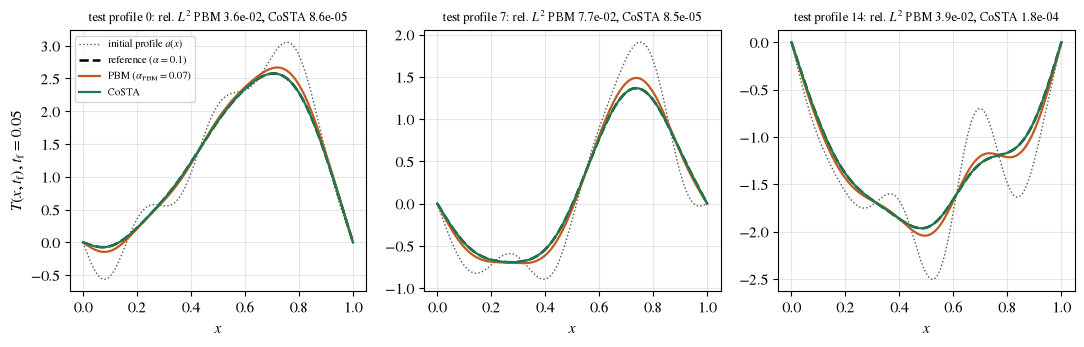

In [7]:
def plot_costa_heat_rod_result():
    fig, axs = plt.subplots(1, len(SHOW), figsize=(11, 3.6), sharey=False)
    for ax, j in zip(axs, SHOW):
        ax.plot(x, U0['test'][j], ':', color=muted(), lw=1.0, label='initial profile $a(x)$')
        ax.plot(x, REF['test'][j, -1], '--', color=fg(), lw=1.8, label='reference ($\\alpha=0.1$)')
        ax.plot(x, test['pbm'][j], 'C1', lw=1.6, label='PBM ($\\alpha_{\\mathrm{PBM}}=0.07$)')
        ax.plot(x, test['costa'][j], 'C2', lw=1.6, label='CoSTA')
        ax.set(xlabel='$x$', title=f"test profile {j}: rel. $L^2$ PBM {test['err']['pbm'][j]:.1e}, "
                                    f"CoSTA {test['err']['costa'][j]:.1e}")
        ax.title.set_fontsize(9)
    axs[0].set_ylabel(f'$T(x, t_{{\\mathrm{{f}}}})$, $t_{{\\mathrm{{f}}}}={T_F:g}$')
    axs[0].legend(fontsize=7.5, loc='best')
    plt.tight_layout()

save_dual(plot_costa_heat_rod_result, 'costa_heat_rod_result', FIG)
plt.show()

Three held-out profiles at $t_{\mathrm f}$. The PBM, diffusing too slowly, keeps too much of every mode and sits
visibly above and below the reference at the peaks; CoSTA lies on the dashed reference curve. The error numbers in
the titles are relative $L^2$ norms at $t_{\mathrm f}$, the metric Module 25 reports for its DeepONet on the same
family.

## 5. A data-only baseline with the same sixty trajectories

Module 25's fixed-output map learns $a\mapsto T(\cdot,t_{\mathrm f})$ from the profile sampled at $40$ sensors.
To see what the same $60$ training trajectories give without a solver, we fit the same kind of map here: an MLP
from the $40$ sensor readings to the $128$ final values, selected on the validation profiles. It sees sixty
input-output pairs. CoSTA sees the same sixty trajectories, but its local, per-step formulation turns them into
$1.5\times10^{6}$ supervised rows and lets the solver carry the shape. That difference in how the data are used,
not a difference in data, is what the comparison isolates.

In [8]:
baseline = None
if RUN_DATA_BASELINE:
    xs = np.linspace(0, 1, M_SENSORS)
    S = {role: np.array([heat1d.profile(c, xs) for c in C]) for role, C in
         [('train', C_TRAIN), ('val', C_VAL), ('test', C_TEST)]}
    S['bump'] = np.exp(-(xs - BUMP_X0)**2 / (2*BUMP_W**2))[None, :]
    Sm, Ss = S['train'].mean(0), S['train'].std(0) + 1e-12
    Rm, Rs = REF['train'][:, -1].mean(0), REF['train'][:, -1].std(0) + 1e-12
    Z = {role: torch.tensor((S[role] - Sm)/Ss) for role in S}
    Yt_b = torch.tensor((REF['train'][:, -1] - Rm)/Rs)
    torch.manual_seed(SEED)
    net_b = MLP([M_SENSORS, 64, 64, N_X]); opt_b = torch.optim.Adam(net_b.parameters(), lr=LR)
    predict_b = lambda role: net_b(Z[role]).detach().numpy()*Rs + Rm
    best_b, state_b, step_b = np.inf, None, 0
    t0 = time.time()
    for k in range(MAX_STEPS + 1):
        if k % VAL_EVERY == 0:
            vb = float(np.mean(heat1d.relative_l2(predict_b('val'), REF['val'][:, -1])))
            if vb < best_b*(1 - MIN_REL_IMPROVEMENT):
                best_b, state_b, step_b = vb, copy.deepcopy(net_b.state_dict()), k
        opt_b.zero_grad(); lb = ((net_b(Z['train']) - Yt_b)**2).mean(); lb.backward(); opt_b.step()
    net_b.load_state_dict(state_b); net_b.eval()
    T_BASE = time.time() - t0
    baseline = dict(test=heat1d.relative_l2(predict_b('test'), REF['test'][:, -1]),
                    bump=heat1d.relative_l2(predict_b('bump'), REF['bump'][:, -1]),
                    best_step=step_b, best_val=best_b, seconds=T_BASE)
    s = spread(baseline['test'])
    print(f"data-only map (60 pairs, selected at step {step_b}): test rel. L2 mean {s['mean']:.2e}, "
          f"median {s['median']:.2e}, max {s['max']:.2e}; bump {baseline['bump'][0]:.2e}; {T_BASE:.0f} s")

data-only map (60 pairs, selected at step 3800): test rel. L2 mean 9.71e-02, median 6.98e-02, max 3.67e-01; bump 7.95e-01; 3 s


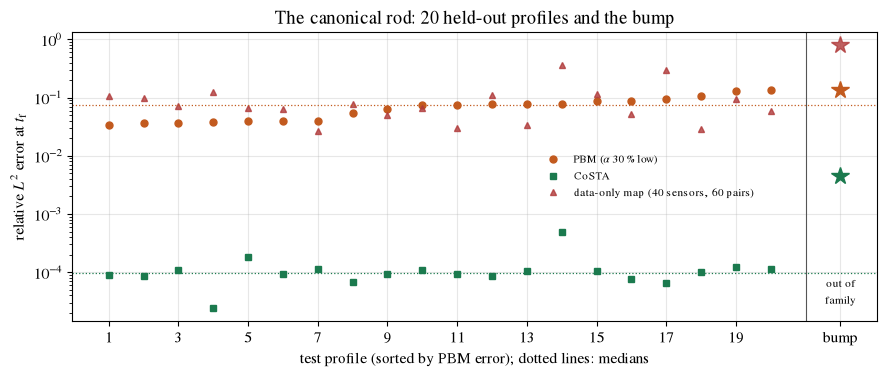

In [9]:
def plot_costa_heat_rod_errors():
    fig, ax = plt.subplots(figsize=(9.0, 3.9))
    order = np.argsort(test['err']['pbm']); k = np.arange(1, N_TEST + 1)
    ax.semilogy(k, test['err']['pbm'][order], 'o', color='C1', ms=5, label='PBM ($\\alpha$ 30 % low)')
    ax.semilogy(k, test['err']['costa'][order], 's', color='C2', ms=5, label='CoSTA')
    if baseline is not None:
        ax.semilogy(k, baseline['test'][order], '^', color='C3', ms=5, alpha=0.8,
                    label=f'data-only map ({M_SENSORS} sensors, 60 pairs)')
    for m, c in [('pbm', 'C1'), ('costa', 'C2')]:
        ax.axhline(np.median(test['err'][m]), color=c, lw=0.9, ls=':')
    kb = N_TEST + 2
    ax.axvline(N_TEST + 1, color=muted(), lw=0.8)
    ax.semilogy([kb], bump['err']['pbm'], marker='*', ms=13, color='C1', ls='none')
    ax.semilogy([kb], bump['err']['costa'], marker='*', ms=13, color='C2', ls='none')
    if baseline is not None:
        ax.semilogy([kb], baseline['bump'], marker='*', ms=13, color='C3', ls='none', alpha=0.8)
    ax.text(kb, ax.get_ylim()[0]*1.6, 'out of\nfamily', ha='center', va='bottom', fontsize=8, color=fg())
    ax.set(xlabel='test profile (sorted by PBM error); dotted lines: medians',
           ylabel='relative $L^2$ error at $t_{\\mathrm{f}}$',
           title=f'The canonical rod: {N_TEST} held-out profiles and the bump')
    ax.set_xticks(list(k[::2]) + [kb]); ax.set_xticklabels([str(i) for i in k[::2]] + ['bump'])
    ax.legend(fontsize=8, loc='center right', bbox_to_anchor=(0.86, 0.5), frameon=False)
    plt.tight_layout()

save_dual(plot_costa_heat_rod_errors, 'costa_heat_rod_errors', FIG)
plt.show()

Every held-out profile tells the same story: the PBM's relative error at $t_{\mathrm f}$ is several percent and
CoSTA's is two to three orders of magnitude smaller. The bump, a shape no training profile resembles, is still
corrected by more than an order of magnitude, but less well than the family. The reason is the one of the
previous notebook, *new parameter $\neq$ new state*, read in the other direction: the network sees local
stencils, and at the peak of the bump the curvature ($1/w^2\approx625$) exceeds the largest curvature in any
training stencil, so there the correction extrapolates in its input space. The data-only map, given the same sixty
trajectories, is no better than the wrong PBM on the family and fails on the bump: a fixed-output map has to
recognize the whole shape, and it has never seen this one. Module 25 reaches low errors with its DeepONet by
training on thousands of profiles, not sixty.

## 6. Ablation: the raw stencil, and a case the stencil cannot see

Two short experiments, both decided on validation and reported on test.

**Raw stencil.** The same network on the raw $[T_{i-1},T_i,T_{i+1}]$, standardized column by column. Nothing changes
in the information content; only the conditioning does.

**A missing source.** In the second case the reference also carries a source $q(x)=20\sin(2\pi x)$ that the PBM
omits (Case 1 of the taxonomy, on top of the wrong parameter). The exact label is now
$(\alpha-\alpha_{\text{PBM}})\,\partial_{xx}T+q(x)$. A stencil-only network cannot represent a function of
position, so for this case the feature set `stencil+x` adds $x_i$, as the `stencil+xt` variant of
`costa_heat_pde.ipynb` does. Both feature sets are trained and compared.

In [10]:
ablation = {}
if RUN_RAW_ABLATION:
    t0 = time.time()
    c_raw, i_raw = fit_costa(REF, U0, basis='raw')
    t_raw = evaluate(c_raw, 'test'); b_raw = evaluate(c_raw, 'bump')
    ablation['raw_stencil'] = dict(best_step=i_raw['best_step'], best_val=i_raw['best_val_rollout'],
                                   test=spread(t_raw['err']['costa']), bump=float(b_raw['err']['costa'][0]),
                                   seconds=time.time() - t0)
    print(f"raw stencil:        validation {i_raw['best_val_rollout']:.2e}, test median "
          f"{ablation['raw_stencil']['test']['median']:.2e}, bump {ablation['raw_stencil']['bump']:.2e}")
    print(f"difference basis:   validation {info['best_val_rollout']:.2e}, test median "
          f"{np.median(test['err']['costa']):.2e}, bump {bump['err']['costa'][0]:.2e}")

source_case = {}
if RUN_SOURCE_CASE:
    q = Q_AMP*np.sin(2*np.pi*x)
    REF_Q = {role: np.array([reference(u, q=q) for u in U]) for role, U in U0.items()}
    pbm_q = {role: np.array([rollout(u) for u in U]) for role, U in U0.items()}
    source_case['pbm'] = dict(test=spread(heat1d.relative_l2(pbm_q['test'], REF_Q['test'][:, -1])),
                              bump=float(heat1d.relative_l2(pbm_q['bump'], REF_Q['bump'][:, -1])[0]))
    print(f"\nsource case q(x) = {Q_AMP:g} sin(2 pi x): PBM test median {source_case['pbm']['test']['median']:.2e}, "
          f"bump {source_case['pbm']['bump']:.2e}")
    for kind in ['stencil', 'stencil+x']:
        t0 = time.time()
        c_q, i_q = fit_costa(REF_Q, U0, kind=kind)
        P_t = np.array([rollout(u, c_q) for u in U0['test']]); P_b = rollout(U0['bump'][0], c_q)
        source_case[kind] = dict(best_step=i_q['best_step'], best_val=i_q['best_val_rollout'],
                                 test=spread(heat1d.relative_l2(P_t, REF_Q['test'][:, -1])),
                                 bump=float(heat1d.relative_l2(P_b, REF_Q['bump'][0, -1])), seconds=time.time() - t0)
        print(f"  features = {kind:9s}: validation {i_q['best_val_rollout']:.2e}, test median "
              f"{source_case[kind]['test']['median']:.2e} (max {source_case[kind]['test']['max']:.2e}), "
              f"bump {source_case[kind]['bump']:.2e}")
    pick = min(['stencil', 'stencil+x'], key=lambda k: source_case[k]['best_val'])
    print(f'  validation would choose: {pick}')

raw stencil:        validation 6.98e-03, test median 7.10e-03, bump 9.04e-03
difference basis:   validation 9.65e-05, test median 9.79e-05, bump 4.58e-03

source case q(x) = 20 sin(2 pi x): PBM test median 6.70e-01, bump 8.54e-01


  features = stencil  : validation 8.60e-01, test median 6.86e-01 (max 3.49e+00), bump 9.51e-01


  features = stencil+x: validation 1.63e-03, test median 1.27e-03 (max 5.92e-03), bump 1.35e-03
  validation would choose: stencil+x


The raw stencil carries the same information but trains to a worse correction: the second difference the network
must extract is buried three digits below the inputs, and the standardized regression does not resolve it well.
Presenting the stencil in the difference basis is the only preprocessing choice in this notebook, and it was
made on validation.

In the source case the stencil-only network cannot win: the exact label depends on $x$ through $q$, and a
function of three temperatures cannot know where on the rod it is. With $x_i$ added, the correction recovers
both the thirty percent of diffusion and the missing source, on the family and on the bump. The choice of inputs
is a modelling decision, and the right inputs depend on what is missing, which is the lesson of the wind-turbine
section too.

In [11]:
results = dict(
    config={k: globals()[k] for k in DEFAULTS} | dict(RUN_RAW_ABLATION=RUN_RAW_ABLATION,
                                                       RUN_SOURCE_CASE=RUN_SOURCE_CASE, Q_AMP=Q_AMP,
                                                       RUN_DATA_BASELINE=RUN_DATA_BASELINE, M_SENSORS=M_SENSORS),
    rod=dict(alpha=ALPHA, n_x=N_X, n_steps=N_STEPS, dt=dt, t_f=T_F, family_modes=heat1d.NMODE,
             ftcs_vs_analytic_max_rel_l2=heat1d.check_reference()),
    selected=dict(best_step=info['best_step'], stopped_at=info['stopped_at'],
                  best_val_rollout_rel_l2=info['best_val_rollout'], train_seconds=T_TRAIN),
    test=dict(n_profiles=N_TEST, pbm=spread(test['err']['pbm']), costa=spread(test['err']['costa']),
              per_profile=dict(pbm=test['err']['pbm'].tolist(), costa=test['err']['costa'].tolist()),
              switch_off_identical_to_pbm=test['switch_off_identical'],
              improvement_factor=dict(median=float(np.median(gain)), min=float(gain.min()), max=float(gain.max()))),
    bump=dict(pbm=float(bump['err']['pbm'][0]), costa=float(bump['err']['costa'][0]),
              switch_off_identical_to_pbm=bump['switch_off_identical']),
    data_only_baseline=None if baseline is None else dict(
        test=spread(baseline['test']), bump=float(baseline['bump'][0]), best_step=baseline['best_step'],
        best_val=baseline['best_val'], seconds=baseline['seconds']),
    ablation=ablation, source_case=source_case, test_seconds=T_TEST)
with open(RESULTS_FILE, 'w') as fh:
    json.dump(results, fh, indent=1)
print('saved', os.path.relpath(RESULTS_FILE))

if AT_DEFAULTS:
    assert np.all(test['err']['costa'] < 0.1*test['err']['pbm']), 'CoSTA should beat the PBM tenfold on every test profile'
    assert bump['err']['costa'] < 0.1*bump['err']['pbm']
else:
    print('regression check skipped (non-default parameters)')

saved ../data/costa_heat_rod_results.json


**Summary.**

* Same rod as Modules 22 and 25: $\alpha=0.1$, the eight-mode family, $128$ points, FTCS to $t_{\mathrm f}=0.05$,
  scored by the relative $L^2$ error at $t_{\mathrm f}$.
* The PBM has the right equation and the wrong parameter ($\alpha_{\text{PBM}}=0.07$); its error at $t_{\mathrm f}$
  is several percent. CoSTA learns the missing thirty percent of the diffusion term from local stencils and
  reduces that error by orders of magnitude on held-out profiles and on an out-of-family bump.
* Switching the correction off reproduces the PBM bit for bit: the identity holds, and says nothing more.
* The stencil must be presented in a well-conditioned basis; and when the missing physics depends on position, the
  stencil alone is the wrong input. Both are decisions made on validation, not on the test set.